# MNIST from scratch

A handwritten-digit classifier built with **only NumPy** — no PyTorch, no
TensorFlow, no autograd. Every forward pass, gradient, and weight update is
written out so you can read the mathematics directly in the code.

This notebook walks through the whole pipeline that lives in the `.py` files
next to it:

1. Load and inspect the data
2. Build the multi-layer perceptron (MLP)
3. Verify backpropagation against numerical gradients
4. Train with mini-batch gradient descent
5. Evaluate on the test set and look at the mistakes
6. Inspect a single prediction

The model is:

```
784 inputs -> Linear -> ReLU -> Linear -> ReLU -> 10 outputs -> softmax + cross-entropy
```


In [21]:
import os
import sys
from argparse import Namespace

# The notebook lives in notebooks/; the project modules live in the repo root.
for path in (os.getcwd(),
             os.path.abspath(os.path.join(os.getcwd(), os.pardir))):
    if os.path.exists(os.path.join(path, "network.py")) and path not in sys.path:
        sys.path.insert(0, path)

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import data
from network import MLP, Dropout, make_optimizer
from convnet import ConvNet
from train import train_model, lr_at

print("numpy", np.__version__)


numpy 2.4.6


## 1. The data

MNIST is 70,000 grayscale 28x28 images of digits (0–9): 60,000 train, 10,000
test. `data.load()` downloads and caches the archive, then applies three
preprocessing steps that matter a lot for training:

1. **Flatten** each 28x28 image into a 784-vector (the first layer is a matrix
   multiply).
2. **Scale** pixels from `[0, 255]` to `[0, 1]`. Gradient descent moves in
   proportion to the input magnitude, so comparable inputs make the loss
   surface far easier to descend.
3. **One-hot encode** the labels: `3 -> [0,0,0,1,0,0,0,0,0,0]`, which pairs
   with the softmax cross-entropy loss.

In [22]:
# Training arrays: flattened, scaled to [0,1], one-hot labels.
(x_train, y_train), (x_test, y_test) = data.load()
# Extra views kept in image / integer-label form for plotting.
(x_train_img, y_train_lbl), (x_test_img, y_test_lbl) = data.load(
    flatten=False, one_hot_labels=False)

print("train:", x_train.shape, y_train.shape)
print("test: ", x_test.shape, y_test.shape)
print("pixel range:", x_train.min(), "-", x_train.max())

train: (60000, 784) (60000, 10)
test:  (10000, 784) (10000, 10)
pixel range: 0.0 - 1.0


### A look at the digits

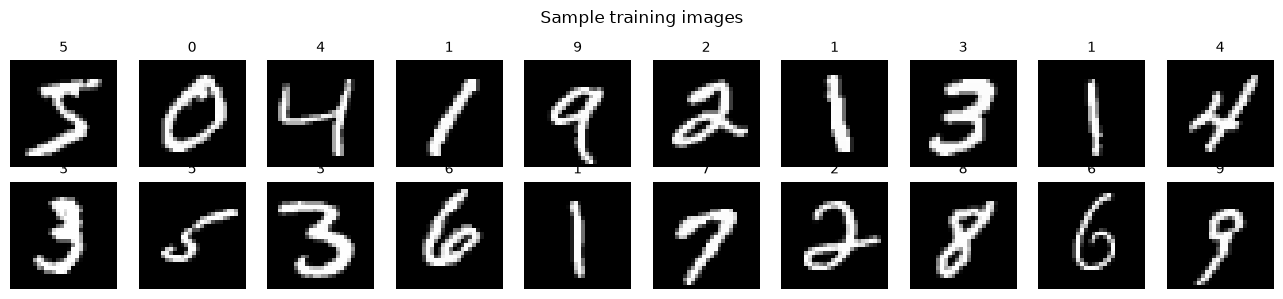

In [23]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for ax, img, label in zip(axes.ravel(), x_train_img[:20], y_train_lbl[:20]):
    ax.imshow(img, cmap="gray")
    ax.set_title(int(label), fontsize=10)
    ax.axis("off")
fig.suptitle("Sample training images")
fig.tight_layout()
plt.show()

## 2. The network

`network.py` defines three layers and wires them into an `MLP`:

- **`Linear`** — `Z = XW + b`, with He initialisation
  (`std = sqrt(2 / fan_in)`) so activation variance stays roughly constant
  through the stack.
- **`ReLU`** — `max(0, Z)`. Without this non-linearity, stacked linear layers
  would collapse into a single linear layer.
- **`SoftmaxCrossEntropy`** — turns logits into probabilities and measures the
  loss, with the famously clean gradient `dL/dZ = (p - y) / B`.

`MLP([784, 256, 128, 10])` builds `Linear+ReLU -> Linear+ReLU -> Linear(10)`.

In [24]:
model = MLP([784, 256, 128, 10], seed=0)

for layer in model.layers:
    print(type(layer).__name__)

n_params = sum(l.W.size + l.b.size for l in model.weight_layers)
print(f"\ntrainable parameters: {n_params:,}")

Linear
ReLU
Linear
ReLU
Linear

trainable parameters: 235,146


## 3. Gradient check

Before trusting any training run, we should confirm the hand-written backward
pass is correct. The definition of a derivative gives us a brute-force
estimate:

```
dL/dw  ~=  (L(w + eps) - L(w - eps)) / (2 * eps)
```

for a tiny `eps`. If that matches backprop, the chain rule implementation is
right. We run the check in **float64**, because central differences divide a
tiny numerator by `2*eps` and float32 round-off would swamp the signal.

In [25]:
gmodel = MLP([20, 16, 12, 5], seed=0)
for layer in gmodel.weight_layers:
    layer.W = layer.W.astype(np.float64)
    layer.b = layer.b.astype(np.float64)

grng = np.random.default_rng(1)
x = grng.normal(size=(8, 20))
y = np.zeros((8, 5))
y[np.arange(8), grng.integers(0, 5, 8)] = 1.0

gmodel.loss(x, y)      # forward, caches activations
gmodel.backward()      # fills layer.dW / layer.db


def num_grad(i, name, idx, eps=1e-5):
    """Central-difference estimate of dL/d(param[idx]) for layer i."""
    param = getattr(gmodel.weight_layers[i], name).reshape(-1)
    orig = param[idx]
    param[idx] = orig + eps
    lp = gmodel.loss(x, y)
    param[idx] = orig - eps
    lm = gmodel.loss(x, y)
    param[idx] = orig
    return (lp - lm) / (2 * eps)


worst = 0.0
for i, layer in enumerate(gmodel.weight_layers):
    for name, grad in (("W", layer.dW), ("b", layer.db)):
        flat = grad.reshape(-1)
        for idx in range(0, flat.size, max(1, flat.size // 3)):
            ng = num_grad(i, name, idx)
            ag = float(flat[idx])
            worst = max(worst, abs(ag - ng) / max(1e-8, abs(ag) + abs(ng)))

print(f"max relative error: {worst:.2e}")
print("PASS" if worst < 1e-4 else "FAIL")

max relative error: 9.51e-09
PASS


## 4. Training

The training loop is classic mini-batch SGD:

```
for each epoch:
    shuffle the training data
    for each mini-batch:
        forward  -> logits
        loss     -> softmax cross-entropy
        backward -> gradients
        step     -> nudge the weights down the gradient
```

A batch of ~128 gives a good estimate of the true gradient at a fraction of
the cost of the full 60,000, and the noise even helps escape shallow traps.
Here we use **Adam**, which takes per-parameter adaptive steps and converges
in a handful of epochs.

In [26]:
EPOCHS = 34
BATCH_SIZE = 128
LR = 1e-3
OPTIMIZER = "adam"

model = MLP([784, 256, 128, 10], seed=0)
optimizer = make_optimizer(OPTIMIZER, model.weight_layers, lr=LR)
rng = np.random.default_rng(0)

history = {"train_loss": [], "train_acc": [], "test_acc": []}

for epoch in range(1, EPOCHS + 1):
    idx = rng.permutation(len(x_train))
    running, seen = 0.0, 0
    for start in range(0, len(x_train), BATCH_SIZE):
        b = idx[start:start + BATCH_SIZE]
        loss = model.loss(x_train[b], y_train[b])   # forward + loss
        model.backward()                            # backprop
        optimizer.step()                            # update weights
        running += loss * len(b)
        seen += len(b)

    train_loss = running / seen
    train_acc = model.accuracy(x_train, y_train)
    test_acc = model.accuracy(x_test, y_test)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)
    print(f"epoch {epoch}/{EPOCHS}  loss {train_loss:.4f}  "
          f"train_acc {train_acc * 100:5.2f}%  test_acc {test_acc * 100:5.2f}%")

epoch 1/34  loss 0.2715  train_acc 96.54%  test_acc 96.18%
epoch 2/34  loss 0.1018  train_acc 98.13%  test_acc 97.22%
epoch 3/34  loss 0.0659  train_acc 98.71%  test_acc 97.59%
epoch 4/34  loss 0.0477  train_acc 99.04%  test_acc 97.67%
epoch 5/34  loss 0.0355  train_acc 99.25%  test_acc 97.83%
epoch 6/34  loss 0.0282  train_acc 99.41%  test_acc 98.02%
epoch 7/34  loss 0.0215  train_acc 99.06%  test_acc 97.36%
epoch 8/34  loss 0.0174  train_acc 99.52%  test_acc 97.77%
epoch 9/34  loss 0.0152  train_acc 99.25%  test_acc 97.63%
epoch 10/34  loss 0.0132  train_acc 99.52%  test_acc 97.95%
epoch 11/34  loss 0.0084  train_acc 99.68%  test_acc 97.93%
epoch 12/34  loss 0.0133  train_acc 99.65%  test_acc 97.88%
epoch 13/34  loss 0.0090  train_acc 99.64%  test_acc 97.78%
epoch 14/34  loss 0.0099  train_acc 99.78%  test_acc 97.99%
epoch 15/34  loss 0.0069  train_acc 99.72%  test_acc 97.95%
epoch 16/34  loss 0.0074  train_acc 99.91%  test_acc 98.23%
epoch 17/34  loss 0.0089  train_acc 99.56%  test_

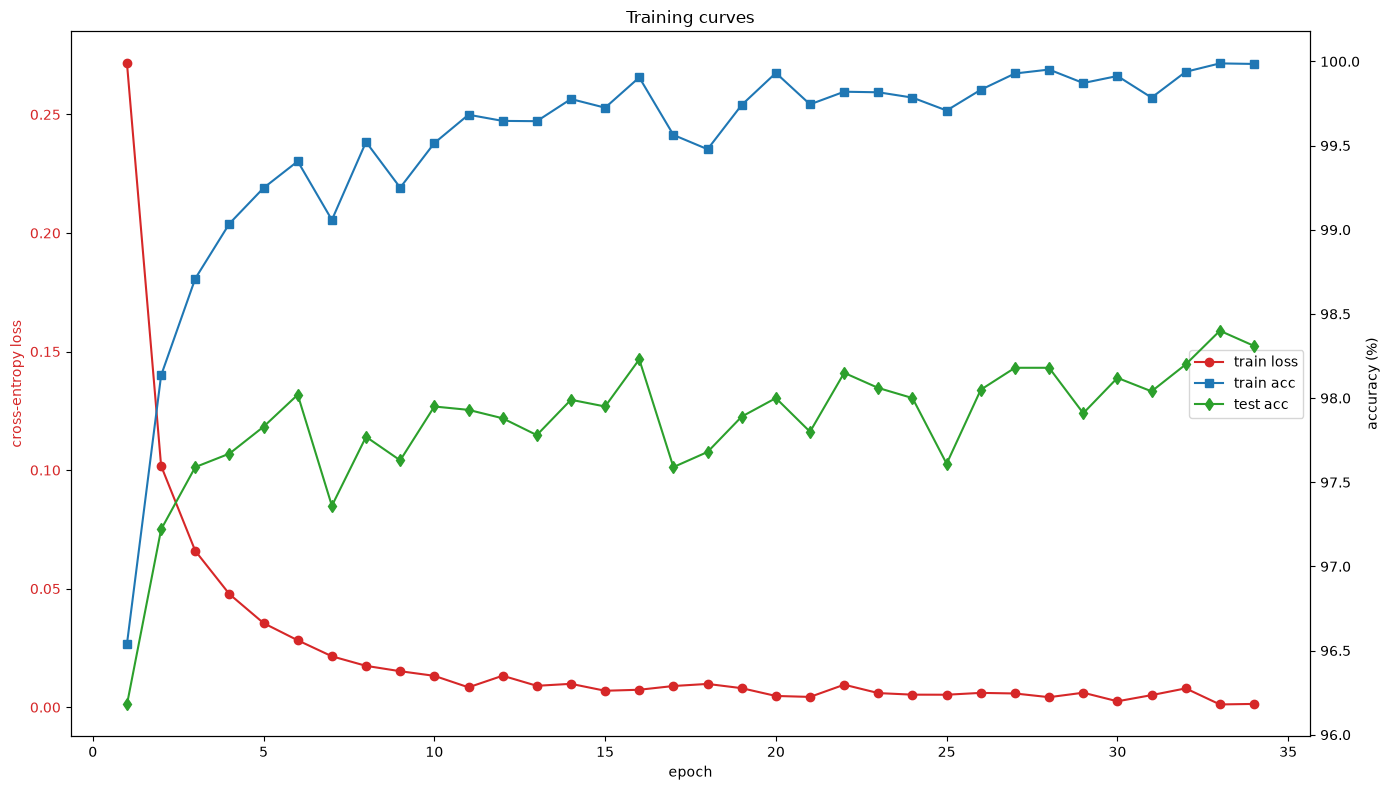

In [46]:
epochs = np.arange(1, len(history["train_loss"]) + 1)

fig, ax = plt.subplots(figsize=(14,8))
ax.plot(epochs, history["train_loss"], "o-", color="tab:red", label="train loss")
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy loss", color="tab:red")
ax.tick_params(axis="y", labelcolor="tab:red")

ax2 = ax.twinx()
ax2.plot(epochs, np.array(history["train_acc"]) * 100, "s-",
         color="tab:blue", label="train acc")
ax2.plot(epochs, np.array(history["test_acc"]) * 100, "d-",
         color="tab:green", label="test acc")
ax2.set_ylabel("accuracy (%)")

lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc="center right")
ax.set_title("Training curves")
fig.tight_layout()
plt.show()

## 5. Evaluation

Inference is fully vectorised: passing the whole `(10000, 784)` test set does
all 10,000 predictions in one set of matrix multiplies.

In [28]:
probs = model.predict_proba(x_test)          # (10000, 10)
preds = probs.argmax(axis=1)

acc = (preds == y_test_lbl).mean()
print(f"test accuracy: {acc * 100:.2f}%")

print("\nper-class accuracy:")
for c in range(10):
    m = y_test_lbl == c
    print(f"  {c}: {(preds[m] == c).sum():>3}/{m.sum():<3} "
          f"{(preds[m] == c).mean() * 100:5.1f}%")

test accuracy: 98.31%

per-class accuracy:
  0: 973/980  99.3%
  1: 1127/1135  99.3%
  2: 1014/1032  98.3%
  3: 991/1010  98.1%
  4: 960/982  97.8%
  5: 873/892  97.9%
  6: 943/958  98.4%
  7: 1008/1028  98.1%
  8: 954/974  97.9%
  9: 988/1009  97.9%


### Where the model goes wrong

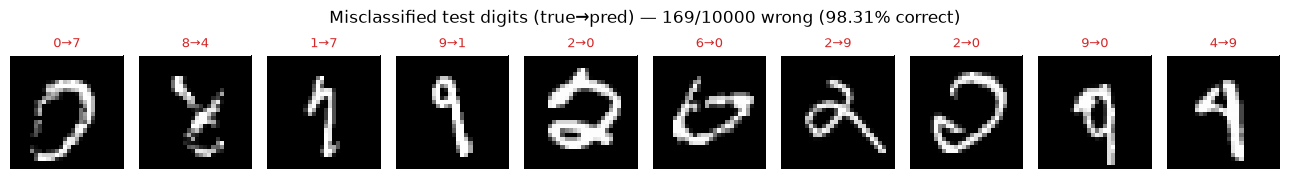

In [29]:
wrong = np.where(preds != y_test_lbl)[0]
rng = np.random.default_rng(0)
chosen = rng.choice(wrong, size=min(10, len(wrong)), replace=False)

fig, axes = plt.subplots(1, len(chosen), figsize=(13, 1.8))
for ax, i in zip(np.atleast_1d(axes), chosen):
    ax.imshow(x_test_img[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{y_test_lbl[i]}\u2192{preds[i]}", fontsize=9, color="tab:red")
    ax.axis("off")
fig.suptitle(f"Misclassified test digits (true\u2192pred) — "
             f"{len(wrong)}/{len(x_test)} wrong "
             f"({(1 - len(wrong) / len(x_test)) * 100:.2f}% correct)")
fig.tight_layout()
plt.show()

## 6. One prediction in detail

`predict_proba` applies a numerically stable softmax to the logits, giving a
full distribution over the ten digits for a single image.

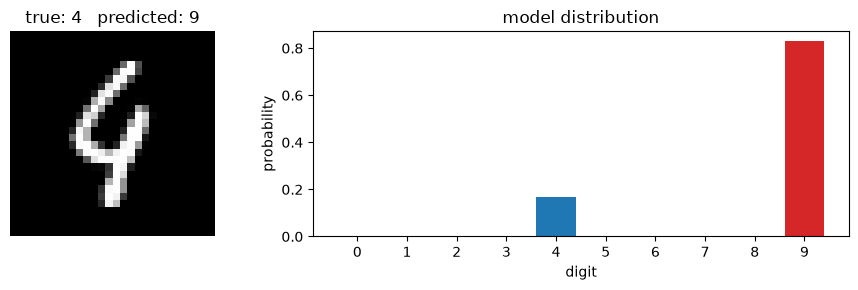

In [30]:
i = int(np.where(preds != y_test_lbl)[0][0])   # pick a mistake to inspect
p = model.predict_proba(x_test[i:i + 1])[0]

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(9, 3),
                                     gridspec_kw={"width_ratios": [1, 2]})
ax_img.imshow(x_test_img[i], cmap="gray", vmin=0, vmax=1)
ax_img.set_title(f"true: {y_test_lbl[i]}   predicted: {preds[i]}")
ax_img.axis("off")

ax_bar.bar(range(10), p, color=["tab:red" if c == preds[i] else "tab:blue"
                                 for c in range(10)])
ax_bar.set_xticks(range(10))
ax_bar.set_xlabel("digit")
ax_bar.set_ylabel("probability")
ax_bar.set_title("model distribution")
fig.tight_layout()
plt.show()

## 7. Dropout

`Dropout` zeroes each hidden activation with probability `p` during training,
and does nothing at inference time. We use *inverted* dropout: surviving units
are scaled by `1/(1-p)` so the expected activation is unchanged, which is why
`predict_proba` needs no rescaling.

The layer only acts in training mode. `MLP.eval()` turns it off, and
`predict` / `predict_proba` / `accuracy` switch to eval mode automatically.


In [31]:
# A Dropout layer on its own: ~p of activations are zeroed while training,
# and the survivors are scaled by 1/(1-p) so the mean is preserved.
d = Dropout(0.3, rng=np.random.default_rng(0))
d.train()
a = d.forward(np.ones((1000, 100)))
print("fraction zeroed while training:", (a == 0).mean().round(3))
print("mean preserved (~1):", a.mean().round(3))
d.eval()
print("eval returns input unchanged:", np.allclose(d.forward(np.ones((5, 3))), 1.0))

# Inside an MLP, predict_proba always runs in eval mode (dropout off).
do = MLP([784, 256, 128, 10], seed=0, dropout=0.3)
print("predict_proba deterministic:",
      np.allclose(do.predict_proba(x_train[:16]), do.predict_proba(x_train[:16])))


fraction zeroed while training: 0.299
mean preserved (~1): 1.001
eval returns input unchanged: True
predict_proba deterministic: True


In [32]:
# Does dropout reduce the train/test gap? Train briefly with and without it.
run = Namespace(lr=1e-3, lr_schedule="none", lr_decay=1.0, lr_step_size=5,
                lr_final_frac=0.0, epochs=3, batch_size=128, seed=0)

for p in (0.0, 0.3):
    m = MLP([784, 256, 128, 10], seed=0, dropout=p)
    opt = make_optimizer("adam", m.weight_layers, lr=1e-3)
    _, h = train_model(m, x_train[:6000], y_train[:6000], x_test, y_test,
                       optimizer=opt, args=run, log=lambda *a: None)
    tr, te = h["train_acc"][-1] * 100, h["test_acc"][-1] * 100
    print(f"dropout={p}:  train {tr:5.2f}%   test {te:5.2f}%   gap {tr - te:5.2f}%")


dropout=0.0:  train 96.52%   test 92.52%   gap  4.00%
dropout=0.3:  train 94.70%   test 92.08%   gap  2.62%


## 8. Nesterov momentum and learning-rate schedules

Nesterov momentum evaluates the step a little *ahead* of the current point,
which damps overshoot near the minimum. A learning-rate schedule trades large
early steps (fast progress) for small late steps (fine convergence). `lr_at`
from `train.py` gives the learning rate for a given epoch under each schedule.


In [33]:
run = Namespace(lr=0.05, lr_schedule="none", lr_decay=1.0,
                lr_step_size=5, lr_final_frac=0.0, epochs=4,
                batch_size=128, seed=0)

for label, nesterov in (("SGD", False), ("SGD + Nesterov", True)):
    m = MLP([784, 256, 128, 10], seed=0)
    opt = make_optimizer("sgd", m.weight_layers, lr=0.05, nesterov=nesterov)
    _, h = train_model(m, x_train[:6000], y_train[:6000], x_test, y_test,
                       optimizer=opt, args=run, log=lambda *a: None)
    print(f"{label:14}: train {h['train_acc'][-1] * 100:5.2f}%  "
          f"test {h['test_acc'][-1] * 100:5.2f}%")


SGD           : train 97.95%  test 93.28%
SGD + Nesterov: train 97.98%  test 93.35%


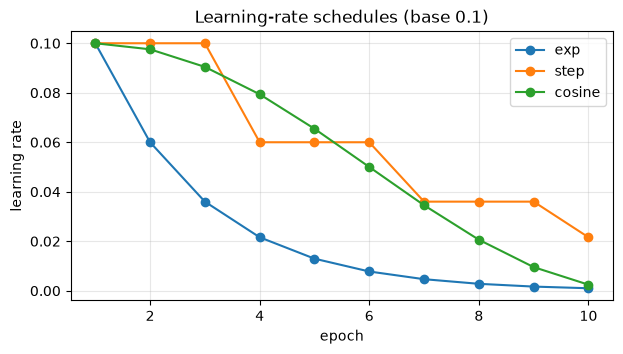

In [34]:
# The same base learning rate under three schedules.
epochs = np.arange(1, 11)
sched = Namespace(lr=1e-1, lr_decay=0.6, lr_step_size=3, lr_final_frac=0.0,
                  epochs=10, lr_schedule="exp")

plt.figure(figsize=(7, 3.5))
for name in ("exp", "step", "cosine"):
    sched.lr_schedule = name
    plt.plot(epochs, [lr_at(1e-1, e, sched) for e in epochs], "o-", label=name)
plt.xlabel("epoch")
plt.ylabel("learning rate")
plt.title("Learning-rate schedules (base 0.1)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 9. Depth study: bias vs variance

The MLP already takes any number of hidden layers. Holding the width fixed and
varying the depth shows the trade-off: too shallow underfits (high bias),
too deep starts to overfit (high variance -- train accuracy pulls ahead of
test). We use a small subset so this runs quickly.


depth 1: train 97.11%  test 93.63%  gap  3.48%
depth 2: train 98.79%  test 94.42%  gap  4.37%
depth 3: train 99.09%  test 94.59%  gap  4.50%


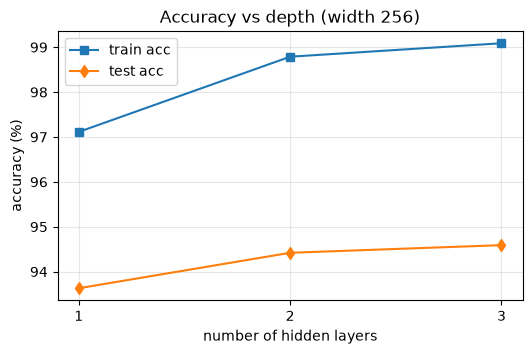

In [35]:
run = Namespace(lr=1e-3, lr_schedule="none", lr_decay=1.0,
                lr_step_size=5, lr_final_frac=0.0, epochs=5,
                batch_size=128, seed=0)

depths, train_acc, test_acc = [], [], []
for depth in (1, 2, 3):
    m = MLP([784] + [256] * depth + [10], seed=0)
    opt = make_optimizer("adam", m.weight_layers, lr=1e-3)
    _, h = train_model(m, x_train[:8000], y_train[:8000], x_test, y_test,
                       optimizer=opt, args=run, log=lambda *a: None)
    depths.append(depth)
    train_acc.append(h["train_acc"][-1] * 100)
    test_acc.append(h["test_acc"][-1] * 100)
    print(f"depth {depth}: train {train_acc[-1]:5.2f}%  test {test_acc[-1]:5.2f}%  "
          f"gap {train_acc[-1] - test_acc[-1]:5.2f}%")

plt.figure(figsize=(6, 3.5))
plt.plot(depths, train_acc, "s-", label="train acc")
plt.plot(depths, test_acc, "d-", label="test acc")
plt.xticks(depths)
plt.xlabel("number of hidden layers")
plt.ylabel("accuracy (%)")
plt.title("Accuracy vs depth (width 256)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 10. What the first layer learned

The first `Linear` layer's weight matrix has shape `(784, hidden)`: column *j*
is the weight vector feeding hidden unit *j*. Reshaping it back to 28x28 shows
the template each unit responds to most strongly -- red is positive, blue is
negative.


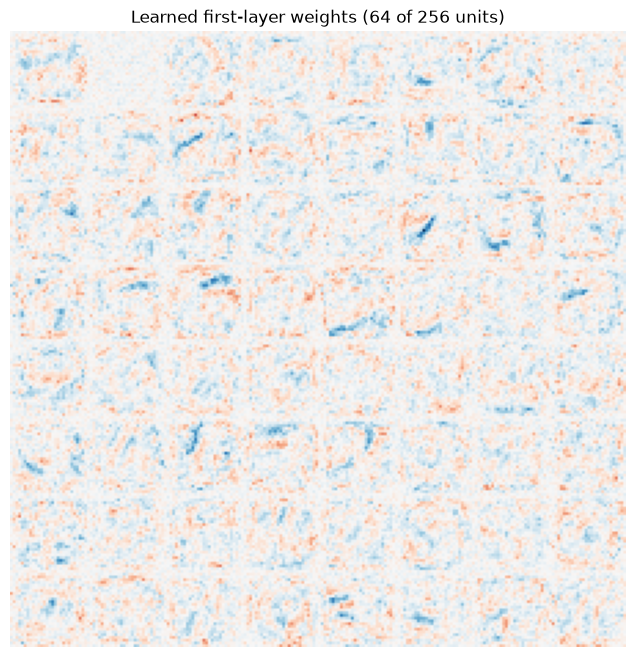

In [36]:
W = model.weight_layers[0].W            # (784, 256) from section 4
side = 28
filters = [W[:, j].reshape(side, side) for j in range(W.shape[1])]

show = filters[:64]
vmax = max(float(np.abs(f).max()) for f in show)
cols = 8
grid = np.zeros((cols * side, cols * side), dtype=np.float32)
for k, f in enumerate(show):
    r, c = divmod(k, cols)
    grid[r * side:(r + 1) * side, c * side:(c + 1) * side] = f

plt.figure(figsize=(8, 8))
plt.imshow(grid, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
plt.title("Learned first-layer weights (64 of 256 units)")
plt.axis("off")
plt.show()


## 11. A small convolutional network

The MLP flattens the image and forgets 2-D structure. The `ConvNet` in
`convnet.py` keeps the grid and slides learnable 3x3 filters across it
(`Conv2d` via im2col), downsampling with `MaxPool2d`:

`1x28x28 -> Conv(8) -> ReLU -> Pool -> Conv(16) -> ReLU -> Pool -> Flatten -> Linear(128) -> ReLU -> Linear(10)`

Its conv/pool backward passes are verified against finite differences below,
then it is trained for a few epochs.


In [37]:
cnn = ConvNet(seed=0)
print([type(l).__name__ for l in cnn.layers])
print("trainable parameters:",
      sum(l.W.size + l.b.size for l in cnn.weight_layers))


['Conv2d', 'ReLU', 'MaxPool2d', 'Conv2d', 'ReLU', 'MaxPool2d', 'Flatten', 'Linear', 'ReLU', 'Linear']
trainable parameters: 103018


In [38]:
# Finite-difference check of the conv + pool backward pass.
rng = np.random.default_rng(0)
gc = ConvNet(in_shape=(1, 8, 8), num_classes=5, seed=0, channels=(2, 3), fc=6)
for l in gc.weight_layers:
    l.W = l.W.astype(np.float64)
    l.b = l.b.astype(np.float64)

xg = rng.normal(size=(2, 1, 8, 8))
yg = np.zeros((2, 5))
yg[np.arange(2), [1, 3]] = 1.0

gc.loss(xg, yg)
gc.backward()

conv = gc.weight_layers[0]
flat = conv.W.reshape(-1)                 # shape (2, 1, 3, 3) -> 18 values
eps, rels = 1e-5, []
for idx in (3, 10, 17):
    orig = flat[idx]
    flat[idx] = orig + eps; lp = gc.loss(xg, yg)
    flat[idx] = orig - eps; lm = gc.loss(xg, yg)
    flat[idx] = orig
    num = (lp - lm) / (2 * eps)
    ana = conv.dW.reshape(-1)[idx]
    rels.append(abs(ana - num) / max(1e-8, abs(ana) + abs(num)))
print("max relative error (conv weights):", max(rels))


max relative error (conv weights): 1.0845908125591244e-10


In [39]:
# Train the CNN for a few epochs (Adam, small subset for speed).
run = Namespace(lr=1e-3, lr_schedule="none", lr_decay=1.0, lr_step_size=5,
                lr_final_frac=0.0, epochs=5, batch_size=128, seed=0)

x_train_ch = x_train_img[:8000, None]      # (N, 1, 28, 28)
x_test_ch = x_test_img[:, None]
cnn = ConvNet(seed=0)
opt = make_optimizer("adam", cnn.weight_layers, lr=1e-3)
cnn, ch = train_model(cnn, x_train_ch, y_train[:8000], x_test_ch, y_test,
                      optimizer=opt, args=run)
print(f"\nCNN test accuracy: {ch['test_acc'][-1] * 100:.2f}%")


epoch  1/5  loss 0.7067  train_acc 92.79%  test_acc 91.87%  lr 0.001  (9.6s)
epoch  2/5  loss 0.2064  train_acc 95.62%  test_acc 94.31%  lr 0.001  (9.9s)
epoch  3/5  loss 0.1438  train_acc 96.76%  test_acc 95.67%  lr 0.001  (9.8s)
epoch  4/5  loss 0.1081  train_acc 97.02%  test_acc 95.36%  lr 0.001  (9.3s)
epoch  5/5  loss 0.0900  train_acc 97.90%  test_acc 96.27%  lr 0.001  (9.2s)

CNN test accuracy: 96.27%


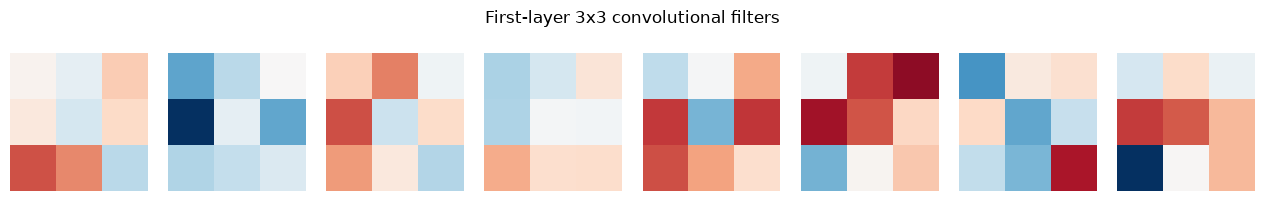

In [40]:
# The learned 3x3 filters of the first conv layer.
filters = [cnn.weight_layers[0].W[o, 0]
           for o in range(cnn.weight_layers[0].W.shape[0])]
vmax = max(float(np.abs(f).max()) for f in filters) or 1.0
fig, axes = plt.subplots(1, len(filters), figsize=(1.6 * len(filters), 2))
for ax, f in zip(np.atleast_1d(axes), filters):
    ax.imshow(f, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.axis("off")
fig.suptitle("First-layer 3x3 convolutional filters")
fig.tight_layout()
plt.show()


## Where to go next

We have now built every model and technique on the original wish-list, all
from scratch in NumPy:

- **Dropout** -- `network.py` (`Dropout`, inverted, with train/eval mode).
- **Nesterov momentum and LR schedules** -- `network.SGDMomentum(nesterov=True)`
  and `train.lr_at` (`exp` / `step` / `cosine`).
- **Deeper MLPs / bias-variance** -- see `experiments.py`.
- **First-layer visualisation** -- section 10 here and `visualize.py`.
- **A convolutional network** -- `convnet.py` (`Conv2d`, `MaxPool2d`, `Flatten`).

Other things to try:

- Add dropout to the CNN and compare against the MLP.
- Train the CNN to convergence: `python train.py --model cnn --optimizer adam --epochs 15`.
- Add a second convolutional block or data augmentation (small random shifts).
- Replace max pooling with average pooling (`MaxPool2d` generalises easily).
